# Prepare eukaryotic tool outputs

Clean functional-annotation outputs against exact reference `RNA_ID` values, export reproducible tables, and compare RNA-level coverage. The all-hit and significant-hit Kofam variants are retained for overlap analysis; only significant Kofam annotations enter the downstream functional table.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from benchannot.eukaryotic.functional_analysis import (
    select_first_submitted_transcript,
)
from benchannot.eukaryotic.prepare_output_tool import (
    SOURCE_ORDER,
    TOOL_ORDER,
    build_cleaning_summary,
    build_functional_table,
    build_rna_presence,
    plot_rna_upset_panels,
    prepare_eggnog,
    prepare_interproscan,
    prepare_kofam,
    prepare_pannzer,
    prepare_reference,
    read_fasta_ids,
    save_table,
)
from benchannot.paths import project_paths, validate_required_inputs

In [2]:
DATASET = "reproduced"  # "origin" or "reproduced"
PATHS = project_paths(DATASET)

DATA_DIR = PATHS.eukaryote_tools
EUKARYOTIC_OUTPUT = PATHS.analysis_output / "eukaryotic"
OUTPUT_DIR = EUKARYOTIC_OUTPUT / "tool_preparation"
TABLE_DIR = OUTPUT_DIR / "tables"
PLOT_DIR = PATHS.figures / "eukaryotic"

ORGANISMS = [
    {
        "organism": "saccharomyces_cerevisiae",
        "display_name": "Saccharomyces cerevisiae",
        "mitochondrial_prefix": "rna-Q",
    },
    {
        "organism": "drosophila_melanogaster",
        "display_name": "Drosophila melanogaster",
        "mitochondrial_prefix": "rna-Dmel",
    },
]
for config in ORGANISMS:
    organism = config["organism"]
    config["reference"] = (
        EUKARYOTIC_OUTPUT
        / "audit"
        / "reference"
        / organism
        / "prepared_reference"
        / "transcript_reference.tsv"
    )
    config["kofam"] = DATA_DIR / "kofamscan" / f"{organism}.kofam.txt"
    config["pannzer"] = DATA_DIR / "pannzer" / f"{organism}_pannzer.txt"
    config["eggnog"] = (
        DATA_DIR / "eggnog" / f"{organism}_eggnog.emapper.annotations"
    )
    config["interproscan"] = (
        DATA_DIR / "interproscan" / f"{organism}.interpro.tsv"
    )
    config["gffread_faa"] = (
        DATA_DIR / "gffread" / f"{organism}_gffread.faa"
    )

print(f"Dataset: {DATASET}")
print(f"Tool inputs: {DATA_DIR}")
print(f"Tables: {TABLE_DIR}")
print(f"Plots:  {PLOT_DIR}")


Dataset: reproduced
Tool inputs: /home/bruno/BenchAnnot/data/reproduced/eukaryote_output_tools
Tables: /home/bruno/BenchAnnot/analysis_benchannot/2_run/output/reproduced/eukaryotic/tool_preparation/tables
Plots:  /home/bruno/BenchAnnot/figures/eukaryotic


In [3]:
required_inputs = {}
for config in ORGANISMS:
    organism = config["organism"]
    required_inputs.update(
        {
            f"{organism} prepared reference": config["reference"],
            f"{organism} GFFread FAA ({DATASET})": config["gffread_faa"],
            f"{organism} KofamScan output ({DATASET})": config["kofam"],
            f"{organism} PANNZER external output ({DATASET}; no fallback)": config["pannzer"],
            f"{organism} eggNOG output ({DATASET})": config["eggnog"],
            f"{organism} InterProScan output ({DATASET})": config["interproscan"],
        }
    )

validate_required_inputs(
    required_inputs,
    context=f"eukaryotic tool preparation ({DATASET})",
)

TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)


## Clean and export tool tables

Coverage counts every returned parser row matched to the reference, including rows with an empty, missing, or placeholder description. Identifiers are compared exactly without trimming or version removal.

In [4]:
references = {}
submitted_ids = {}
tool_results = {}
summary_parts = []

for config in ORGANISMS:
    organism = config["organism"]
    prefix = config["mitochondrial_prefix"]
    reference = prepare_reference(config["reference"])
    submitted_ids[organism] = {
        rna_id
        for rna_id in read_fasta_ids(config["gffread_faa"])
        if not rna_id.startswith(prefix)
    }
    kofam_all = prepare_kofam(config["kofam"], False, prefix)
    kofam_significant = prepare_kofam(config["kofam"], True, prefix)
    tools = {
        "Kofam": kofam_significant,
        "Pannzer": prepare_pannzer(config["pannzer"], prefix),
        "EggNOG": prepare_eggnog(config["eggnog"], prefix),
        "InterProScan": prepare_interproscan(config["interproscan"], prefix),
    }
    references[organism] = reference
    tool_results[organism] = {
        "Kofam_all": kofam_all,
        "Kofam_significant": kofam_significant,
        **{source: tools[source] for source in TOOL_ORDER[1:]},
    }

    save_table(reference, TABLE_DIR / f"{organism}_reference.tsv")
    save_table(kofam_all, TABLE_DIR / f"{organism}_kofam_all.tsv")
    save_table(kofam_significant, TABLE_DIR / f"{organism}_kofam_significant.tsv")
    for source in TOOL_ORDER[1:]:
        save_table(tools[source], TABLE_DIR / f"{organism}_{source.lower()}.tsv")
    functional = build_functional_table(reference, tools)
    save_table(functional, TABLE_DIR / f"{organism}_functional_annotations.tsv")
    summary_parts.append(
        build_cleaning_summary(
            organism, config["display_name"], reference, tools, submitted_ids[organism]
        )
    )
    print(
        f"{organism}: {len(reference):,} reference RNA_ID; "
        f"{len(functional):,} downstream rows"
    )

cleaning_summary = pd.concat(summary_parts, ignore_index=True)
save_table(cleaning_summary, TABLE_DIR / "cleaning_summary.tsv")
print(cleaning_summary.to_string(index=False))

saccharomyces_cerevisiae: 6,002 reference RNA_ID; 6,002 downstream rows
drosophila_melanogaster: 30,789 reference RNA_ID; 30,789 downstream rows
                organism             display_name       source  gffread_input_rna_ids  raw_rows  tool_identified_rna_ids  identified_outside_submission  cleaned_rows  reference_rna_ids  retained_rna_ids  represented_loci  percentage_reference
saccharomyces_cerevisiae Saccharomyces cerevisiae        Kofam                   6002    174368                     6002                              0          3697               6002              3697              3697             61.596135
saccharomyces_cerevisiae Saccharomyces cerevisiae      Pannzer                   6002     69701                     6002                              0          5358               6002              5358              5358             89.270243
saccharomyces_cerevisiae Saccharomyces cerevisiae       EggNOG                   6002      5497                     5495      

## RNA_ID processing summary

Tools are rows and organisms are columns. Each panel shows four cumulative stages: exact RNA_ID values submitted through GFFread, IDs identified by the tool, IDs retained after tool-specific cleaning and exact reference matching, and retained representative RNA_ID values after selecting the first submitted transcript per locus. Kofam uses only significant hits (`marker == "*"`).

In [5]:
stage_labels = (
    'GFFread\ninput',
    'Tool\nidentified',
    'Retained\nRNA_ID',
    'Representative\nRNA_ID\n(one per locus)',
)
stage_colors = ('#264653', '#457b9d', '#2a9d8f', '#c8553d')
representative_rows = []
for config in ORGANISMS:
    organism = config['organism']
    representative = select_first_submitted_transcript(
        references[organism], submitted_ids[organism]
    )
    representative_ids = set(representative['RNA_ID'])
    for source in TOOL_ORDER:
        table_key = 'Kofam_significant' if source == 'Kofam' else source
        table = tool_results[organism][table_key]
        identified_ids = set(table.attrs.get('identified_rna_ids', table['RNA_ID']))
        identified = len(representative_ids & identified_ids)
        retained = len(representative_ids & set(table['RNA_ID']))
        representative_rows.append(
            {
                'organism': organism,
                'display_name': config['display_name'],
                'source': source,
                'representative_input_loci': len(representative),
                'representative_identified_loci': identified,
                'representative_retained_loci': retained,
            }
        )

representative_summary = pd.DataFrame(representative_rows)
representative_summary.to_csv(
    TABLE_DIR / 'cleaning_summary_representative_loci.tsv', sep='\t', index=False
)
plot_summary = cleaning_summary.merge(
    representative_summary,
    on=['organism', 'display_name', 'source'],
    validate='one_to_one',
)
print(
    plot_summary[
        [
            'display_name', 'source', 'gffread_input_rna_ids',
            'tool_identified_rna_ids', 'retained_rna_ids',
            'representative_input_loci', 'representative_identified_loci',
            'representative_retained_loci',
        ]
    ].to_string(index=False)
)


            display_name       source  gffread_input_rna_ids  tool_identified_rna_ids  retained_rna_ids  representative_input_loci  representative_identified_loci  representative_retained_loci
Saccharomyces cerevisiae        Kofam                   6002                     6002              3697                       6002                            6002                          3697
Saccharomyces cerevisiae      Pannzer                   6002                     6002              5358                       6002                            6002                          5358
Saccharomyces cerevisiae       EggNOG                   6002                     5495              5495                       6002                            5495                          5495
Saccharomyces cerevisiae InterProScan                   6002                     5577              4791                       6002                            5577                          4791
 Drosophila melanogaster        Kof

## Submitted first-transcript intersections

The UpSet reference universe contains only RNA_ID values present in the GFFread FASTA, with the first submitted transcript selected for each locus. Tool membership is restricted to those representatives, Kofam includes only significant hits (`marker == "*"`), and RNA_ID values not returned by a tool remain explicit no-hits. Panels are ordered as *S. cerevisiae* and *D. melanogaster*; exported membership tables retain the fixed source order Reference, Kofam, Pannzer, EggNOG, InterProScan.


A) Saccharomyces cerevisiae
Source
Reference       6002
Kofam           3697
Pannzer         5358
EggNOG          5495
InterProScan    4791

B) Drosophila melanogaster
Source
Reference       13885
Kofam            7060
Pannzer         11593
EggNOG          12651
InterProScan    10905
Saved /home/bruno/BenchAnnot/figures/eukaryotic/eukaryotic_upset_merged.png


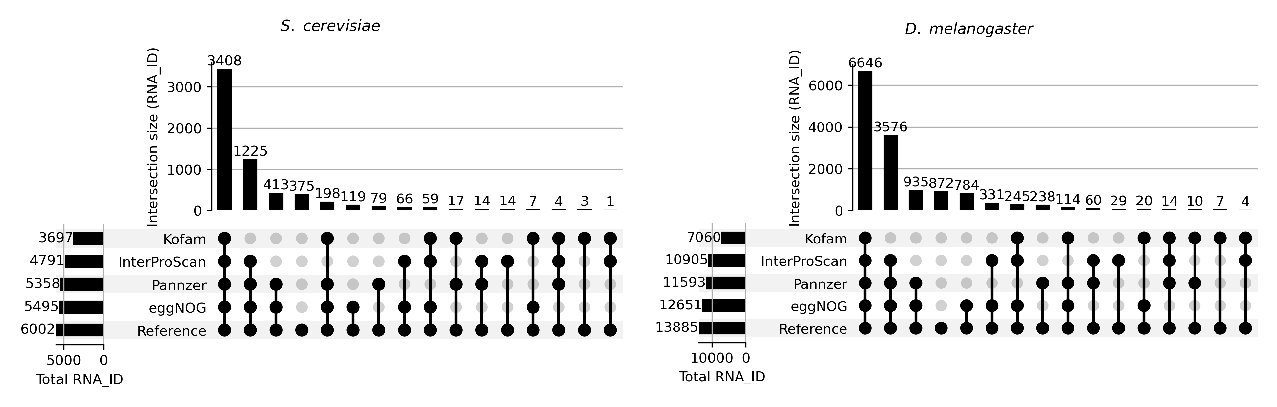

PosixPath('/home/bruno/BenchAnnot/figures/eukaryotic/eukaryotic_upset_merged.png')

In [6]:
submitted_panel_memberships = {}
for panel, config in zip(('A', 'B'), ORGANISMS, strict=True):
    organism = config['organism']
    reference = select_first_submitted_transcript(
        references[organism], submitted_ids[organism]
    )
    representative_ids = set(reference['RNA_ID'])
    tools = {
        'Kofam': tool_results[organism]['Kofam_significant'],
        **{source: tool_results[organism][source] for source in TOOL_ORDER[1:]},
    }
    representative_tools = {
        source: table.loc[table['RNA_ID'].isin(representative_ids)].copy()
        for source, table in tools.items()
    }
    presence, membership = build_rna_presence(reference, representative_tools)
    if not membership.index.isin(submitted_ids[organism]).all():
        raise ValueError(f'{organism}: UpSet contains RNA_ID absent from GFFread')
    if len(reference) != reference['locus_tag'].nunique():
        raise ValueError(f'{organism}: expected one submitted transcript per locus')

    suffix = 'submitted_first_transcript_significant_kofam'
    save_table(presence, TABLE_DIR / f'{organism}_presence_{suffix}.tsv')
    save_table(
        membership.reset_index(),
        TABLE_DIR / f'{organism}_membership_{suffix}.tsv',
    )
    display_math = config['display_name'].replace(' ', r'\ ')
    submitted_panel_memberships[rf'{panel}) $\it{{{display_math}}}$'] = membership
    print(f"\n{panel}) {config['display_name']}")
    print(membership.sum().to_string())

from benchannot.plotting import plot_upset_panels

standardized_memberships = {
    config["organism"]: membership
    for config, membership in zip(
        ORGANISMS, submitted_panel_memberships.values(), strict=True
    )
}
plot_upset_panels(
    standardized_memberships,
    source_order=list(SOURCE_ORDER),
    count_label="RNA_ID",
    save_path=PLOT_DIR / "eukaryotic_upset_merged.png",
)


Saved /home/bruno/BenchAnnot/figures/eukaryotic/representative_processing_merged.png


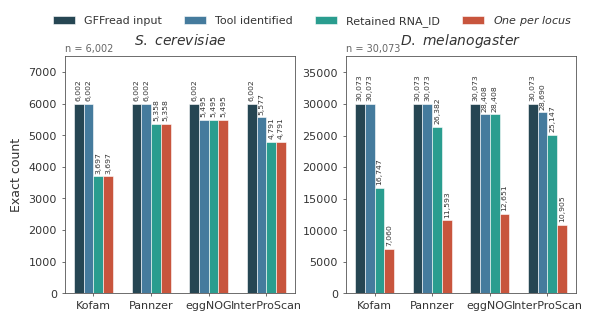

PosixPath('/home/bruno/BenchAnnot/figures/eukaryotic/representative_processing_merged.png')

In [7]:
from benchannot.eukaryotic.prepare_output_tool import (
    plot_representative_stages_panels,
)
from benchannot.plotting import apply_style

apply_style()

cleaning_plot_summary = pd.read_csv(TABLE_DIR / "cleaning_summary.tsv", sep="	")
representative_plot_summary = cleaning_plot_summary.merge(
    pd.read_csv(
        TABLE_DIR / "cleaning_summary_representative_loci.tsv", sep="	"
    ),
    on=["organism", "display_name", "source"],
    validate="one_to_one",
)
plot_representative_stages_panels(
    representative_plot_summary,
    PLOT_DIR / "representative_processing_merged.png",
    title=None,
    species_keys=True,
)
